# YOLOv8s — CASHEW_YOLO_MASTER_V01 · V02 (5 seeds)

**Experiment:** `EXP-Y8S-SMALL-002-5SEED`. **Model:** `yolov8s.pt` pretrained.

Dataset: [CASHEW_YOLO_MASTER_V01.zip](https://drive.google.com/file/d/1uLhp2M3BbwtCwQSIWnSNApYXgGBLnz_a/view) trong [thư mục YOLO](https://drive.google.com/drive/folders/16S4O-7f7Tl2_xb0JrB5b-PJZA0FqKQ1M).

Năm seed cố định `(42, 123, 2026, 3407, 7777)` theo giao thức nghiên cứu của dự án. Mỗi seed khởi tạo lại từ cùng pretrained checkpoint; train/val/test, hyperparameter và version dataset được giữ cố định. Báo cáo từng seed và **mean ± sample SD (ddof=1)** trên Test. Validation chọn `best.pt`; Test chỉ dùng để đánh giá, không chọn seed hoặc chỉnh cấu hình. ZIP kết quả gồm checkpoint, metrics và chính notebook V02 này.


## 01. Cài thư viện

Chạy notebook trên **Colab** hoặc **Kaggle** với GPU. Trên Colab, chọn `Runtime → Change runtime type → GPU`; trên Kaggle, chọn `Settings → Accelerator → GPU`.


In [1]:
# Cài thư viện YOLO và Google Drive API (chạy trước các cell import)
!pip install -q -U ultralytics google-api-python-client google-auth pyyaml


## 02. Import & kiểm tra môi trường

In [2]:

import os
import sys
import json
import glob
import hashlib
import time
import random
import shutil
import zipfile
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

MATRIX_CMAP = LinearSegmentedColormap.from_list(
    "readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)
from PIL import Image, ImageDraw

import torch
import yaml
import ultralytics
import google.auth
from ultralytics import YOLO

try:
    import google.colab  # Google Colab runtime
    RUNTIME = "Colab"
except ImportError:
    RUNTIME = "Kaggle" if Path("/kaggle/working").is_dir() else "Unknown"
if RUNTIME == "Unknown":
    raise RuntimeError("Notebook này hỗ trợ Colab hoặc Kaggle")

print("=" * 70)
print("ENVIRONMENT")
print("=" * 70)
print("Runtime     :", RUNTIME)
print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__)
print("Ultralytics :", ultralytics.__version__)
print("CUDA        :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))
else:
    print("GPU         : Không có GPU - hãy bật GPU trong Kaggle Settings")


ENVIRONMENT
Runtime     : Colab
Python      : 3.13.16
PyTorch     : 2.11.0+cu130
Ultralytics : 8.4.194
CUDA        : True
GPU         : NVIDIA RTX PRO 6000 Blackwell Server Edition


## 03. Cấu hình cố định cho 5 seed


In [3]:
# ============================================================
# CONFIG
# ============================================================
EXPERIMENT_ID = "EXP-Y8S-SMALL-002-5SEED"
SEEDS = (42, 123, 2026, 3407, 7777)
SEED = SEEDS[0]
MODEL_NAME = "yolov8s.pt"

EPOCHS = 50
PATIENCE = 20
IMG_SIZE = 640
BATCH_SIZE = 8
WORKERS = 4
OPTIMIZER = "AdamW"
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 5e-4
MOSAIC = 0.5
MIXUP = 0.0
COPY_PASTE = 0.0
FLIPLR = 0.5

PRED_CONF = 0.25
NMS_IOU = 0.70
MATCH_IOU = 0.50
DEVICE = 0 if torch.cuda.is_available() else "cpu"

DRIVE_FILE_ID = "1uLhp2M3BbwtCwQSIWnSNApYXgGBLnz_a"
ZIP_FILENAME = "CASHEW_YOLO_MASTER_V01.zip"
DRIVE_RESULT_FOLDER_ID = "16S4O-7f7Tl2_xb0JrB5b-PJZA0FqKQ1M"
DATASET_ZIP_OVERRIDE = None  # Đường dẫn ZIP cục bộ, nếu cần; MD5 phải trùng Drive.

WORK_BASE = Path("/content") if RUNTIME == "Colab" else Path("/kaggle/working")
INPUT_ROOT = Path("/content/input") if RUNTIME == "Colab" else Path("/kaggle/input")
WORK_ROOT = WORK_BASE / "cashew_yolov8_v02"
DATASET_DIR = WORK_ROOT / EXPERIMENT_ID / "dataset"
RUNS_DIR = WORK_ROOT / "runs"
EXPORT_DIR = WORK_ROOT / EXPERIMENT_ID / "export"
NOTEBOOK_FILENAME = "train-yolov8-cashew-master-v02-5seeds.ipynb"
PACKAGE_CELL_INDEX = 28

for folder in (WORK_ROOT, RUNS_DIR, EXPORT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print("Experiment:", EXPERIMENT_ID, "| Model:", MODEL_NAME, "| Device:", DEVICE)


Experiment: EXP-Y8S-SMALL-002-5SEED | Model: yolov8s.pt | Device: 0


### 03a. Xác thực Google Drive

Trên **Colab**, cấp quyền Google khi được hỏi. Trên **Kaggle**, bật Internet và tạo secret `GOOGLE_DRIVE_OAUTH_JSON` là OAuth `authorized_user` JSON có quyền Drive. Notebook kiểm tra ZIP nguồn và quyền upload kết quả vào [thư mục YOLO](https://drive.google.com/drive/folders/16S4O-7f7Tl2_xb0JrB5b-PJZA0FqKQ1M) trước khi train. Không ghi thông tin xác thực vào notebook.


In [4]:
# ============================================================
# DRIVE AUTH + DATASET VERSION PREFLIGHT
# ============================================================
from google.oauth2.credentials import Credentials
from google.auth.transport.requests import Request
from googleapiclient.discovery import build

try:
    if RUNTIME == "Colab":
        from google.colab import auth
        auth.authenticate_user()
        drive_credentials, _ = google.auth.default()
    else:
        from kaggle_secrets import UserSecretsClient
        credential_info = json.loads(UserSecretsClient().get_secret("GOOGLE_DRIVE_OAUTH_JSON"))
        if credential_info.get("type") != "authorized_user":
            raise ValueError("Secret phải là OAuth authorized_user JSON")
        drive_credentials = Credentials.from_authorized_user_info(
            credential_info, scopes=["https://www.googleapis.com/auth/drive"]
        )
        if not drive_credentials.valid:
            drive_credentials.refresh(Request())
    drive_service = build("drive", "v3", credentials=drive_credentials, cache_discovery=False)
    result_folder = drive_service.files().get(
        fileId=DRIVE_RESULT_FOLDER_ID,
        fields="id,name,mimeType,capabilities(canAddChildren)",
        supportsAllDrives=True,
    ).execute()
    dataset_metadata = drive_service.files().get(
        fileId=DRIVE_FILE_ID,
        fields="id,name,size,md5Checksum,parents,mimeType",
        supportsAllDrives=True,
    ).execute()
except Exception as exc:
    raise RuntimeError(
        "Không kết nối được Drive. Trên Colab hãy cấp quyền đúng tài khoản; "
        "trên Kaggle hãy bật Internet và gắn Secret GOOGLE_DRIVE_OAUTH_JSON."
    ) from exc

if result_folder.get("mimeType") != "application/vnd.google-apps.folder":
    raise ValueError("DRIVE_RESULT_FOLDER_ID không phải folder")
if not result_folder.get("capabilities", {}).get("canAddChildren", False):
    raise PermissionError("Tài khoản không có quyền ghi vào folder YOLO")
if dataset_metadata.get("name") != ZIP_FILENAME:
    raise ValueError(f"Dataset ZIP sai tên: {dataset_metadata.get('name')}")
if DRIVE_RESULT_FOLDER_ID not in dataset_metadata.get("parents", []):
    raise ValueError("Dataset ZIP không nằm trong folder YOLO")

print("Drive folder :", result_folder["name"], result_folder["id"])
print("Dataset ZIP  :", dataset_metadata["name"], dataset_metadata["size"], "bytes")


Drive folder : YOLO 16S4O-7f7Tl2_xb0JrB5b-PJZA0FqKQ1M
Dataset ZIP  : CASHEW_YOLO_MASTER_V01.zip 168700838 bytes


## 04. Tải và kiểm tra dataset CASHEW_YOLO_MASTER_V01

Notebook lấy đúng file ID trên Drive. Có thể dùng ZIP cùng tên trong Kaggle Input hoặc `DATASET_ZIP_OVERRIDE`; kích thước và MD5 (nếu Drive cung cấp) phải khớp. ZIP được giải nén riêng cho experiment này.


In [5]:
# ============================================================
# DOWNLOAD / VERIFY / EXTRACT THE CASHEW MASTER DATASET
# ============================================================
from googleapiclient.http import MediaIoBaseDownload

def digest_file(path, algorithm="sha256"):
    h = hashlib.new(algorithm)
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

if DATASET_ZIP_OVERRIDE:
    ZIP_PATH = Path(DATASET_ZIP_OVERRIDE)
    if not ZIP_PATH.is_file():
        raise FileNotFoundError(f"DATASET_ZIP_OVERRIDE không tồn tại: {ZIP_PATH}")
else:
    input_zips = sorted(INPUT_ROOT.rglob(ZIP_FILENAME)) if INPUT_ROOT.is_dir() else []
    if len(input_zips) > 1:
        raise RuntimeError(f"Nhiều ZIP cùng tên trong input: {input_zips}")
    if input_zips:
        ZIP_PATH = input_zips[0]
    else:
        ZIP_PATH = WORK_ROOT / ZIP_FILENAME
        temp = ZIP_PATH.with_name(ZIP_PATH.name + ".partial")
        request = drive_service.files().get_media(fileId=DRIVE_FILE_ID, supportsAllDrives=True)
        with temp.open("wb") as stream:
            downloader = MediaIoBaseDownload(stream, request, chunksize=8 * 1024 * 1024)
            done = False
            while not done:
                status, done = downloader.next_chunk(num_retries=3)
                if status is not None:
                    print(f"Dataset download: {status.progress():.0%}")
        temp.replace(ZIP_PATH)

if ZIP_PATH.stat().st_size != int(dataset_metadata["size"]):
    raise ValueError("Dataset ZIP size không khớp file trên Drive")
if dataset_metadata.get("md5Checksum") and digest_file(ZIP_PATH, "md5") != dataset_metadata["md5Checksum"]:
    raise ValueError("Dataset ZIP MD5 không khớp file trên Drive")
if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError(f"File không phải ZIP hợp lệ: {ZIP_PATH}")
DATASET_SHA256 = digest_file(ZIP_PATH)

# Tách riêng dataset của experiment V02; không dùng cache của experiment cũ.
if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)
DATASET_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as archive:
    root = DATASET_DIR.resolve()
    for member in archive.infolist():
        if not (DATASET_DIR / member.filename).resolve().is_relative_to(root):
            raise ValueError(f"Đường dẫn không an toàn trong ZIP: {member.filename}")
    archive.extractall(DATASET_DIR)

YAML_FILES = sorted(DATASET_DIR.rglob("data.yaml")) + sorted(DATASET_DIR.rglob("data.yml"))
if len(YAML_FILES) != 1:
    raise RuntimeError(f"Cần đúng một data.yaml/data.yml: {YAML_FILES}")
ORIGINAL_YAML = YAML_FILES[0]
DATASET_SOURCE_DIR = ORIGINAL_YAML.parent
dataset_source = {
    "drive_file_id": DRIVE_FILE_ID,
    "drive_folder_id": DRIVE_RESULT_FOLDER_ID,
    "zip_filename": ZIP_FILENAME,
    "zip_size_bytes": ZIP_PATH.stat().st_size,
    "zip_sha256": DATASET_SHA256,
    "zip_md5": digest_file(ZIP_PATH, "md5"),
}
(EXPORT_DIR / "dataset_source.json").write_text(
    json.dumps(dataset_source, indent=2), encoding="utf-8"
)
print("Dataset root:", DATASET_SOURCE_DIR)
print("Dataset SHA256:", DATASET_SHA256)


Dataset download: 5%
Dataset download: 10%
Dataset download: 15%
Dataset download: 20%
Dataset download: 25%
Dataset download: 30%
Dataset download: 35%
Dataset download: 40%
Dataset download: 45%
Dataset download: 50%
Dataset download: 55%
Dataset download: 60%
Dataset download: 65%
Dataset download: 70%
Dataset download: 75%
Dataset download: 80%
Dataset download: 85%
Dataset download: 90%
Dataset download: 94%
Dataset download: 99%
Dataset download: 100%
Dataset root: /content/cashew_yolov8_v02/EXP-Y8S-SMALL-002-5SEED/dataset/CASHEW_YOLO_MASTER_V01
Dataset SHA256: 1ce942644c3b822f20c350d27a467074dca0be2fafcfb5f739c8d2484e5dd79e


## 05. Chuẩn hóa `data.yaml` cho bố cục images/labels theo split

`data.yaml` từ ZIP cung cấp class ID và tên class. Notebook tạo YAML mới trỏ đến `images/train`, `images/val`, `images/test`; nhãn tương ứng ở `labels/train`, `labels/val`, `labels/test`. Đường dẫn được kiểm tra sau giải nén.


In [6]:
# ============================================================
# 05. LOAD & FIX DATA.YAML
# ============================================================

import yaml

with open(ORIGINAL_YAML, "r", encoding="utf-8") as f:
    raw_cfg = yaml.safe_load(f)

print("Original data.yaml:")
print(raw_cfg)

Original data.yaml:
{'path': 'D:/Study/Training result dowload/YOLO/YOLO_Master/CASHEW_YOLO_MASTER_V01', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'nc': 3, 'names': ['anthracnose', 'leaf_miner', 'red_rust']}


In [7]:
# ============================================================
# RESOLVE CASHEW MASTER LAYOUT AND WRITE DATA.YAML
# ============================================================
if not isinstance(raw_cfg, dict):
    raise ValueError("data.yaml không chứa cấu hình dạng mapping")
dataset_root = ORIGINAL_YAML.parent.resolve()
split_images = {}
split_labels = {}
for split in ("train", "val", "test"):
    images_dir = dataset_root / "images" / split
    labels_dir = dataset_root / "labels" / split
    if not images_dir.is_dir() or not labels_dir.is_dir():
        raise FileNotFoundError(
            f"Thiếu {images_dir} hoặc {labels_dir}. "
            "ZIP cần có images/{train,val,test} và labels/{train,val,test}."
        )
    split_images[split] = images_dir
    split_labels[split] = labels_dir

TRAIN_IMAGES = split_images["train"]
VAL_IMAGES = split_images["val"]
TEST_IMAGES = split_images["test"]

names = raw_cfg.get("names")
if isinstance(names, dict):
    names = [names.get(i, names.get(str(i))) for i in range(len(names))]
if not isinstance(names, list) or not names or any(not isinstance(n, str) or not n for n in names):
    raise ValueError("data.yaml phải có names là list hoặc dict class ID 0..N-1")
if "nc" in raw_cfg and int(raw_cfg["nc"]) != len(names):
    raise ValueError("nc và số class trong names không khớp")

fixed_cfg = {
    "path": str(dataset_root),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(names),
    "names": names,
}
FIXED_YAML = WORK_ROOT / EXPERIMENT_ID / "data_fixed.yaml"
with FIXED_YAML.open("w", encoding="utf-8") as stream:
    yaml.safe_dump(fixed_cfg, stream, sort_keys=False, allow_unicode=True)

print("Dataset root:", dataset_root)
print("Fixed YAML:", FIXED_YAML)
print("Classes:", names)
print(FIXED_YAML.read_text(encoding="utf-8"))


Dataset root: /content/cashew_yolov8_v02/EXP-Y8S-SMALL-002-5SEED/dataset/CASHEW_YOLO_MASTER_V01
Fixed YAML: /content/cashew_yolov8_v02/EXP-Y8S-SMALL-002-5SEED/data_fixed.yaml
Classes: ['anthracnose', 'leaf_miner', 'red_rust']
path: /content/cashew_yolov8_v02/EXP-Y8S-SMALL-002-5SEED/dataset/CASHEW_YOLO_MASTER_V01
train: images/train
val: images/val
test: images/test
nc: 3
names:
- anthracnose
- leaf_miner
- red_rust



## 06. Kiểm tra ảnh, nhãn và class trước 5 lần train


,images,images_with_boxes,background_images,boxes,anthracnose,leaf_miner,red_rust
train,2361,2361,0,76707,29949,2074,44684
val,841,841,0,43472,12226,567,30679
test,402,402,0,16626,2848,372,13406


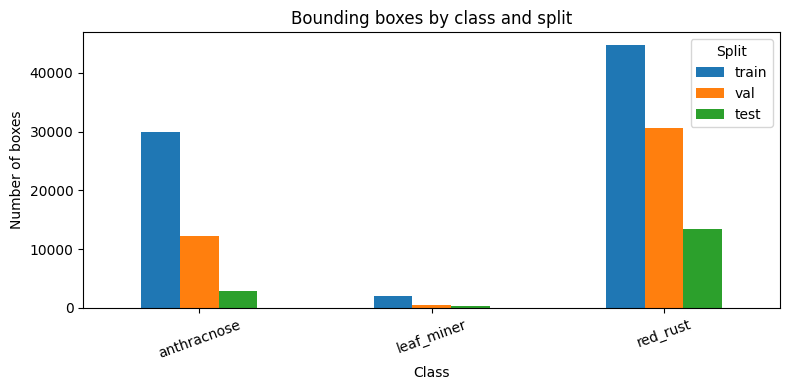

In [8]:
# ============================================================
# DATASET VALIDATION AND STATISTICS
# ============================================================
import math

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_images(folder):
    return sorted(p for p in Path(folder).rglob("*")
                  if p.is_file() and p.suffix.lower() in IMAGE_EXTS)

def image_to_label_path(image_path):
    image_path = Path(image_path).resolve()
    # /images/train/foo.jpg -> /labels/train/foo.txt
    relative = image_path.relative_to(dataset_root / "images")
    return (dataset_root / "labels" / relative).with_suffix(".txt")

def split_stats(split, class_names):
    images = get_images(split_images[split])
    if not images:
        raise ValueError(f"Split {split} không có ảnh")
    class_boxes = defaultdict(int)
    images_with_labels = 0
    total_boxes = 0
    for image in images:
        label = image_to_label_path(image)
        if not label.is_file():
            continue  # Ảnh background có thể không có file nhãn.
        lines = label.read_text(encoding="utf-8-sig").splitlines()
        box_count = 0
        for line_no, line in enumerate(lines, start=1):
            if not line.strip():
                continue
            parts = line.split()
            if len(parts) != 5:
                raise ValueError(f"{label}:{line_no}: cần đúng 5 giá trị YOLO bbox")
            try:
                cls = int(parts[0])
                xc, yc, w, h = (float(x) for x in parts[1:])
            except ValueError as exc:
                raise ValueError(f"{label}:{line_no}: class/tọa độ không hợp lệ") from exc
            if not 0 <= cls < len(class_names):
                raise ValueError(f"{label}:{line_no}: class ID {cls} ngoài names")
            if not all(math.isfinite(x) for x in (xc, yc, w, h)):
                raise ValueError(f"{label}:{line_no}: tọa độ không hữu hạn")
            if not (0 <= xc <= 1 and 0 <= yc <= 1 and 0 < w <= 1 and 0 < h <= 1):
                raise ValueError(f"{label}:{line_no}: bbox phải là tọa độ chuẩn hóa 0..1")
            if xc - w / 2 < -1e-3 or xc + w / 2 > 1.001 or yc - h / 2 < -1e-3 or yc + h / 2 > 1.001:
                raise ValueError(f"{label}:{line_no}: bbox vượt ngoài ảnh")
            class_boxes[cls] += 1
            total_boxes += 1
            box_count += 1
        images_with_labels += box_count > 0
    if total_boxes == 0:
        raise ValueError(f"Split {split} không có bbox; kiểm tra cấu trúc labels/{split}")
    orphan_labels = [p for p in split_labels[split].rglob("*.txt")
                     if not any((split_images[split] / p.relative_to(split_labels[split])).with_suffix(ext).is_file()
                                for ext in IMAGE_EXTS)]
    if orphan_labels:
        print(f"Cảnh báo: {split} có {len(orphan_labels)} nhãn không ghép được ảnh, ví dụ: {orphan_labels[:3]}")
    row = {"images": len(images), "images_with_boxes": images_with_labels,
           "background_images": len(images) - images_with_labels, "boxes": total_boxes}
    row.update({name: class_boxes[i] for i, name in enumerate(class_names)})
    return row

class_names = fixed_cfg["names"]
stats = {split: split_stats(split, class_names) for split in ("train", "val", "test")}
stats_df = pd.DataFrame(stats).T
display(stats_df)
stats_df.to_csv(EXPORT_DIR / "dataset_statistics.csv", index=True)
(EXPORT_DIR / "dataset_statistics.json").write_text(
    json.dumps(stats, indent=2, ensure_ascii=False), encoding="utf-8"
)

fig, ax = plt.subplots(figsize=(max(8, len(class_names) * 2), 4))
stats_df[class_names].T.plot(kind="bar", ax=ax)
ax.set_title("Bounding boxes by class and split")
ax.set_ylabel("Number of boxes")
ax.set_xlabel("Class")
ax.legend(title="Split")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(EXPORT_DIR / "class_box_distribution.png", dpi=180)
plt.show()



### Kiểm tra nhanh annotation

Cell dưới hiển thị một số ảnh Train cùng bounding box ground-truth để đảm bảo annotation đọc đúng.


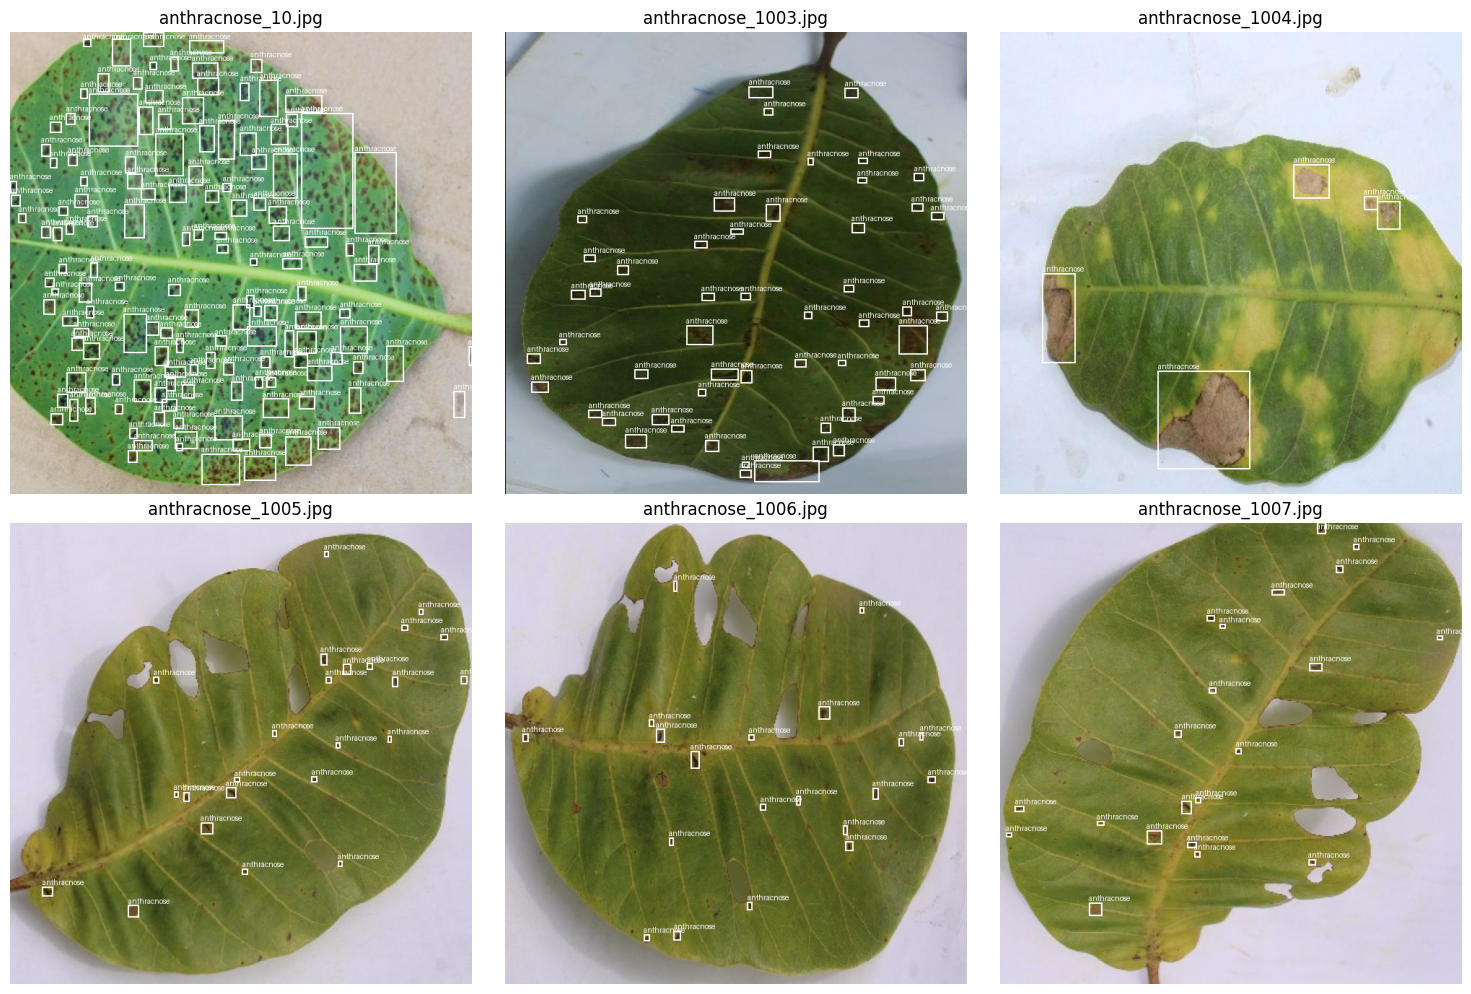

In [9]:

def yolo_xywhn_to_xyxy(xc, yc, w, h, img_w, img_h):
    xc, yc = xc * img_w, yc * img_h
    w, h = w * img_w, h * img_h
    return (
        xc - w / 2,
        yc - h / 2,
        xc + w / 2,
        yc + h / 2
    )

sample_images = get_images(TRAIN_IMAGES)[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for ax, img_path in zip(axes, sample_images):
    img = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(img)

    label_path = image_to_label_path(img_path)

    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue

            cls_id = int(float(parts[0]))
            xc, yc, w, h = map(float, parts[1:5])
            box = yolo_xywhn_to_xyxy(xc, yc, w, h, img.width, img.height)

            draw.rectangle(box, width=2)
            draw.text((box[0], max(0, box[1] - 12)), class_names[cls_id])

    ax.imshow(img)
    ax.axis("off")
    ax.set_title(img_path.name[:35])

plt.tight_layout()
plt.show()


## 07. Khóa giao thức 5 seed

Dừng nếu cùng EXP ID đã có cấu hình hoặc checksum dataset khác.


In [10]:
# Lock dataset and recipe before starting any seed.
import hashlib

TRAIN_ROOT = RUNS_DIR / "train" / EXPERIMENT_ID
TEST_ROOT = RUNS_DIR / "test" / EXPERIMENT_ID
run_spec = {
    "experiment_id": EXPERIMENT_ID,
    "dataset_file_id": DRIVE_FILE_ID,
    "dataset_sha256": DATASET_SHA256,
    "model": MODEL_NAME,
    "seeds": list(SEEDS),
    "epochs": EPOCHS,
    "patience": PATIENCE,
    "imgsz": IMG_SIZE,
    "batch": BATCH_SIZE,
    "optimizer": OPTIMIZER,
    "lr0": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "mosaic": MOSAIC,
    "mixup": MIXUP,
    "copy_paste": COPY_PASTE,
    "fliplr": FLIPLR,
    "ultralytics_version": ultralytics.__version__,
}
RUN_SPEC_SHA256 = hashlib.sha256(
    json.dumps(run_spec, sort_keys=True).encode("utf-8")
).hexdigest()
spec_path = WORK_ROOT / EXPERIMENT_ID / "run_spec.json"
if spec_path.exists():
    if json.loads(spec_path.read_text(encoding="utf-8")) != run_spec:
        raise RuntimeError("Run spec cũ khác dataset/cấu hình. Hãy dùng EXPERIMENT_ID mới.")
else:
    spec_path.write_text(json.dumps(run_spec, indent=2, ensure_ascii=False), encoding="utf-8")
shutil.copy2(spec_path, EXPORT_DIR / "run_spec.json")
print("Seeds:", SEEDS)
print("Dataset SHA256:", DATASET_SHA256)
print("Run spec SHA256:", RUN_SPEC_SHA256)


Seeds: (42, 123, 2026, 3407, 7777)
Dataset SHA256: 1ce942644c3b822f20c350d27a467074dca0be2fafcfb5f739c8d2484e5dd79e
Run spec SHA256: c046ca0263fb18bd58239cd3b98d9033427eda05f697778917b9bccad2cb4155


## 08. Train 5 seed

Mỗi lần train tạo một model từ pretrained weights. Nếu một seed bị ngắt sau khi lưu `last.pt`, chạy lại cell này để resume; seed đã hoàn tất sẽ được bỏ qua.


In [11]:
# Each seed starts from the same pretrained weights, with identical data and settings.
seed_train_rows = []
for seed in SEEDS:
    run_name = f"seed_{seed}"
    run_dir = TRAIN_ROOT / run_name
    best_pt = run_dir / "weights" / "best.pt"
    last_pt = run_dir / "weights" / "last.pt"
    done_file = run_dir / "seed_complete.json"
    if done_file.exists():
        done = json.loads(done_file.read_text(encoding="utf-8"))
        if done.get("run_spec_sha256") != RUN_SPEC_SHA256 or done.get("seed") != seed:
            raise RuntimeError(f"Seed {seed} có marker của cấu hình khác")
        if not best_pt.is_file() or not last_pt.is_file():
            raise FileNotFoundError(f"Seed {seed} đã đánh dấu xong nhưng thiếu checkpoint")
        print(f"Seed {seed}: đã hoàn tất, dùng lại checkpoint")
    else:
        resumed = last_pt.is_file()
        if run_dir.exists() and not resumed:
            raise RuntimeError(f"Run chưa hoàn tất và thiếu last.pt: {run_dir}")
        print(f"Seed {seed}: {'resume' if resumed else 'train mới'}")
        started = time.perf_counter()
        if resumed:
            YOLO(str(last_pt)).train(resume=True)
        else:
            random.seed(seed)
            np.random.seed(seed)
            torch.manual_seed(seed)
            if torch.cuda.is_available():
                torch.cuda.manual_seed_all(seed)
            model = YOLO(MODEL_NAME)
            model.train(
                data=str(FIXED_YAML), epochs=EPOCHS, patience=PATIENCE,
                imgsz=IMG_SIZE, batch=BATCH_SIZE, device=DEVICE, workers=WORKERS,
                optimizer=OPTIMIZER, lr0=LEARNING_RATE,
                weight_decay=WEIGHT_DECAY, mosaic=MOSAIC, mixup=MIXUP,
                copy_paste=COPY_PASTE, fliplr=FLIPLR,
                seed=seed, deterministic=True,
                project=str(TRAIN_ROOT), name=run_name,
                exist_ok=False, plots=True, save=True, verbose=True,
            )
        session_seconds = time.perf_counter() - started
        if not best_pt.is_file() or not last_pt.is_file():
            raise FileNotFoundError(f"Seed {seed} thiếu best.pt/last.pt sau train")
        done = {
            "seed": seed, "run_spec_sha256": RUN_SPEC_SHA256,
            "resumed": resumed, "last_session_seconds": session_seconds,
        }
        done_file.write_text(json.dumps(done, indent=2), encoding="utf-8")
    seed_train_rows.append({
        "seed": seed, "best_pt": str(best_pt), "last_pt": str(last_pt),
        "resumed": bool(done["resumed"]),
        "last_session_seconds": done["last_session_seconds"],
    })

train_df = pd.DataFrame(seed_train_rows)
display(train_df)
train_df.to_csv(EXPORT_DIR / "per_seed_training.csv", index=False)


Seed 42: train mới
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cashew_yolov8_v02/EXP-Y8S-SMALL-002-5SEED/data_fixed.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, m

,seed,best_pt,last_pt,resumed,last_session_seconds
0,42,/content/cashew_yolov8_v02/runs/train/EXP-Y8S-...,/content/cashew_yolov8_v02/runs/train/EXP-Y8S-...,False,405.121532
1,123,/content/cashew_yolov8_v02/runs/train/EXP-Y8S-...,/content/cashew_yolov8_v02/runs/train/EXP-Y8S-...,False,404.479789
2,2026,/content/cashew_yolov8_v02/runs/train/EXP-Y8S-...,/content/cashew_yolov8_v02/runs/train/EXP-Y8S-...,False,408.945851
3,3407,/content/cashew_yolov8_v02/runs/train/EXP-Y8S-...,/content/cashew_yolov8_v02/runs/train/EXP-Y8S-...,False,407.220854
4,7777,/content/cashew_yolov8_v02/runs/train/EXP-Y8S-...,/content/cashew_yolov8_v02/runs/train/EXP-Y8S-...,False,345.140304


## 09. Đánh giá riêng từng seed trên Test

Dùng cùng tập Test cho cả 5 seed. Precision/Recall/F1 và mAP là chỉ số Ultralytics; TP/FP/FN và Mean IoU dùng `PRED_CONF`/`MATCH_IOU` cố định.


In [12]:

# ============================================================
# IOU UTILITIES
# ============================================================

def xywhn_to_xyxy(xc, yc, w, h, img_w, img_h):
    xc *= img_w
    yc *= img_h
    w *= img_w
    h *= img_h

    return np.array([
        xc - w / 2,
        yc - h / 2,
        xc + w / 2,
        yc + h / 2
    ], dtype=np.float32)

def box_iou(box_a, box_b):
    x1 = max(float(box_a[0]), float(box_b[0]))
    y1 = max(float(box_a[1]), float(box_b[1]))
    x2 = min(float(box_a[2]), float(box_b[2]))
    y2 = min(float(box_a[3]), float(box_b[3]))

    inter_w = max(0.0, x2 - x1)
    inter_h = max(0.0, y2 - y1)
    inter = inter_w * inter_h

    area_a = max(0.0, float(box_a[2] - box_a[0])) * max(0.0, float(box_a[3] - box_a[1]))
    area_b = max(0.0, float(box_b[2] - box_b[0])) * max(0.0, float(box_b[3] - box_b[1]))

    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0

def load_ground_truth(image_path):
    label_path = image_to_label_path(image_path)

    if not label_path.exists():
        return []

    with Image.open(image_path) as im:
        img_w, img_h = im.size

    text = label_path.read_text(encoding="utf-8").strip()

    if not text:
        return []

    gt = []

    for line in text.splitlines():
        parts = line.split()

        if len(parts) < 5:
            continue

        cls_id = int(float(parts[0]))
        xc, yc, w, h = map(float, parts[1:5])

        gt.append({
            "cls": cls_id,
            "box": xywhn_to_xyxy(xc, yc, w, h, img_w, img_h)
        })

    return gt

def greedy_match(gt, preds, match_iou=0.5):
    used_gt = set()
    matches = []

    preds = sorted(preds, key=lambda x: x["conf"], reverse=True)

    for pred in preds:
        best_iou = -1
        best_idx = None

        for j, target in enumerate(gt):
            if j in used_gt:
                continue

            if pred["cls"] != target["cls"]:
                continue

            iou = box_iou(pred["box"], target["box"])

            if iou > best_iou:
                best_iou = iou
                best_idx = j

        if best_idx is not None and best_iou >= match_iou:
            used_gt.add(best_idx)
            matches.append({
                "cls": pred["cls"],
                "conf": pred["conf"],
                "iou": best_iou
            })

    tp = len(matches)
    fp = len(preds) - tp
    fn = len(gt) - tp

    return matches, tp, fp, fn


In [13]:
# Evaluate each completed seed on the same locked Test split.
# No hyperparameter or seed is selected using Test metrics.
test_images = get_images(TEST_IMAGES)
gt_by_image = {str(path): load_ground_truth(path) for path in test_images}
per_seed_rows = []
per_class_rows = []

for seed in SEEDS:
    run_name = f"seed_{seed}"
    best_pt = TRAIN_ROOT / run_name / "weights" / "best.pt"
    done_file = TRAIN_ROOT / run_name / "seed_complete.json"
    if not done_file.is_file() or not best_pt.is_file():
        raise RuntimeError(f"Seed {seed} chưa train xong")
    print(f"Đánh giá seed {seed} trên Test")
    best_model = YOLO(str(best_pt))
    metrics = best_model.val(
        data=str(FIXED_YAML), split="test", imgsz=IMG_SIZE,
        batch=BATCH_SIZE, device=DEVICE, workers=WORKERS,
        conf=0.001, iou=NMS_IOU, plots=True,
        project=str(TEST_ROOT), name=run_name, exist_ok=True,
    )
    box = metrics.box
    precision, recall = float(box.mp), float(box.mr)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    ap_index = {int(class_id): i for i, class_id in enumerate(box.ap_class_index)}
    for class_id, class_name in enumerate(class_names):
        if class_id in ap_index:
            p, r, ap50, ap = box.class_result(ap_index[class_id])
            class_f1 = 2 * p * r / (p + r + 1e-12)
            values = {"precision": float(p), "recall": float(r), "f1": float(class_f1),
                      "mAP50": float(ap50), "mAP50_95": float(ap)}
        else:
            values = {"precision": None, "recall": None, "f1": None,
                      "mAP50": None, "mAP50_95": None}
        per_class_rows.append({"seed": seed, "class_id": class_id,
                               "class_name": class_name,
                               "test_gt_boxes": stats["test"][class_name], **values})

    total_tp = total_fp = total_fn = 0
    matched_ious = []
    predictions = best_model.predict(
        source=[str(p) for p in test_images], stream=True,
        imgsz=IMG_SIZE, conf=PRED_CONF, iou=NMS_IOU,
        device=DEVICE, verbose=False,
    )
    prediction_count = 0
    for image_path, result in zip(test_images, predictions):
        preds = []
        if result.boxes is not None and len(result.boxes):
            xyxy = result.boxes.xyxy.cpu().numpy()
            classes = result.boxes.cls.cpu().numpy().astype(int)
            confidences = result.boxes.conf.cpu().numpy()
            preds = [{"cls": int(c), "conf": float(conf), "box": coords}
                     for coords, c, conf in zip(xyxy, classes, confidences)]
        matches, tp, fp, fn = greedy_match(gt_by_image[str(image_path)], preds, MATCH_IOU)
        total_tp += tp
        total_fp += fp
        total_fn += fn
        matched_ious.extend(m["iou"] for m in matches)
        prediction_count += 1
    if prediction_count != len(test_images):
        raise RuntimeError(f"Seed {seed}: số prediction không bằng số ảnh Test")
    fixed_p = total_tp / (total_tp + total_fp + 1e-12)
    fixed_r = total_tp / (total_tp + total_fn + 1e-12)
    fixed_f1 = 2 * fixed_p * fixed_r / (fixed_p + fixed_r + 1e-12)
    per_seed_rows.append({
        "seed": seed, "precision": precision, "recall": recall, "f1": f1,
        "mAP50": float(box.map50), "mAP75": float(box.map75),
        "mAP50_95": float(box.map),
        "fixed_conf": PRED_CONF, "match_iou": MATCH_IOU,
        "tp": total_tp, "fp": total_fp, "fn": total_fn,
        "fixed_precision": fixed_p, "fixed_recall": fixed_r,
        "fixed_f1": fixed_f1,
        "mean_matched_iou": float(np.mean(matched_ious)) if matched_ious else None,
    })
    pd.DataFrame(per_seed_rows).to_csv(EXPORT_DIR / "per_seed_test_metrics.partial.csv", index=False)

per_seed_df = pd.DataFrame(per_seed_rows)
per_class_df = pd.DataFrame(per_class_rows)
display(per_seed_df)
per_seed_df.to_csv(EXPORT_DIR / "per_seed_test_metrics.csv", index=False)
per_class_df.to_csv(EXPORT_DIR / "per_class_per_seed.csv", index=False)


Đánh giá seed 42 trên Test
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4387.9±2442.9 MB/s, size: 62.0 KB)
val: Scanning /content/cashew_yolov8_v02/EXP-Y8S-SMALL-002-5SEED/dataset/CASHEW_YOLO_MASTER_V01/labels/test... 402 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 402/402 4.8Kit/s 0.1s
val: New cache created: /content/cashew_yolov8_v02/EXP-Y8S-SMALL-002-5SEED/dataset/CASHEW_YOLO_MASTER_V01/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 17.2it/s 3.0s0.1s
                   all        402      16626      0.629      0.596      0.627      0.325
           anthracnose        304       2848      0.584      0.673      0.644      0.322
            leaf_miner        132        372      0.571      0.

,seed,precision,recall,f1,mAP50,mAP75,mAP50_95,fixed_conf,match_iou,tp,fp,fn,fixed_precision,fixed_recall,fixed_f1,mean_matched_iou
0,42,0.628803,0.596260,0.612099,0.627436,0.293881,0.324906,0.25,0.5,9986,4216,6640,0.703140,0.600626,0.647853,0.768725
1,123,0.630840,0.583643,0.606324,0.609658,0.248090,0.300054,0.25,0.5,11685,6833,4941,0.631008,0.702815,0.664978,0.754053
2,2026,0.620237,0.590577,0.605044,0.617588,0.273813,0.308991,0.25,0.5,10667,4508,5959,0.702932,0.641585,0.670859,0.760657
3,3407,0.657987,0.593923,0.624316,0.630259,0.282620,0.320383,0.25,0.5,11767,6146,4859,0.656897,0.707747,0.681375,0.766779
4,7777,0.624132,0.613964,0.619006,0.633696,0.299807,0.329337,0.25,0.5,9940,3842,6686,0.721231,0.597859,0.653775,0.771958


## 10. Tổng hợp mức độ ổn định

Bảng trình bày từng seed và mean ± **sample SD** (`ddof=1`), kể cả từng class. Đây là biến thiên do seed trên cùng một Test set, không phải khoảng tin cậy cho dữ liệu thực địa mới.


,metric,n_seeds,mean,sample_sd,min,max
0,precision,5,0.632400,0.014886,0.620237,0.657987
1,recall,5,0.595673,0.011276,0.583643,0.613964
2,f1,5,0.613358,0.008249,0.605044,0.624316
3,mAP50,5,0.623727,0.009892,0.609658,0.633696
4,mAP75,5,0.279642,0.020296,0.248090,0.299807
5,mAP50_95,5,0.316734,0.012012,0.300054,0.329337
6,fixed_precision,5,0.683042,0.037580,0.631008,0.721231
7,fixed_recall,5,0.650126,0.053271,0.597859,0.707747
8,fixed_f1,5,0.663768,0.013369,0.647853,0.681375
9,mean_matched_iou,5,0.764434,0.007116,0.754053,0.771958


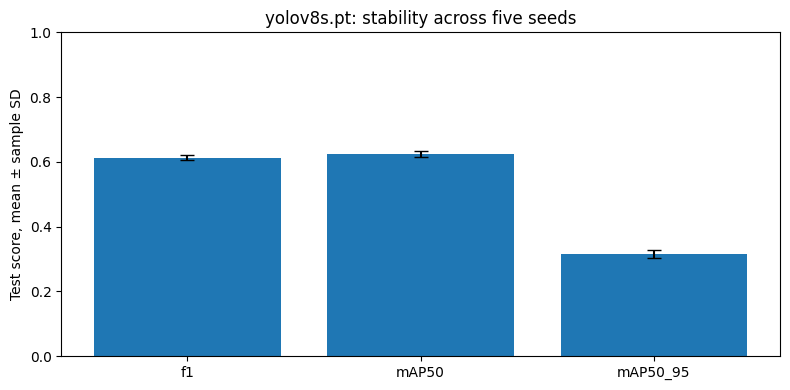

9361

In [14]:
# Descriptive variability across five independent training seeds.
metric_columns = ["precision", "recall", "f1", "mAP50", "mAP75", "mAP50_95",
                  "fixed_precision", "fixed_recall", "fixed_f1", "mean_matched_iou"]
summary_rows = []
for metric in metric_columns:
    values = pd.to_numeric(per_seed_df[metric], errors="coerce").dropna()
    summary_rows.append({
        "metric": metric, "n_seeds": int(len(values)),
        "mean": float(values.mean()) if len(values) else None,
        "sample_sd": float(values.std(ddof=1)) if len(values) > 1 else None,
        "min": float(values.min()) if len(values) else None,
        "max": float(values.max()) if len(values) else None,
    })
summary_df = pd.DataFrame(summary_rows)
display(summary_df)
summary_df.to_csv(EXPORT_DIR / "five_seed_summary.csv", index=False)

class_summary_rows = []
for (class_id, class_name), group in per_class_df.groupby(["class_id", "class_name"], sort=True):
    for metric in ("precision", "recall", "f1", "mAP50", "mAP50_95"):
        values = pd.to_numeric(group[metric], errors="coerce").dropna()
        class_summary_rows.append({
            "class_id": int(class_id), "class_name": class_name,
            "test_gt_boxes": int(group["test_gt_boxes"].iloc[0]),
            "metric": metric, "n_seeds": int(len(values)),
            "mean": float(values.mean()) if len(values) else None,
            "sample_sd": float(values.std(ddof=1)) if len(values) > 1 else None,
        })
class_summary_df = pd.DataFrame(class_summary_rows)
class_summary_df.to_csv(EXPORT_DIR / "per_class_five_seed_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
plot_metrics = ["f1", "mAP50", "mAP50_95"]
plot_rows = summary_df.set_index("metric").loc[plot_metrics]
ax.bar(plot_metrics, plot_rows["mean"], yerr=plot_rows["sample_sd"], capsize=5)
ax.set_ylabel("Test score, mean ± sample SD")
ax.set_ylim(0, 1)
ax.set_title(f"{MODEL_NAME}: stability across five seeds")
fig.tight_layout()
fig.savefig(EXPORT_DIR / "five_seed_stability.png", dpi=180)
plt.show()

report = {
    "run_spec": run_spec, "run_spec_sha256": RUN_SPEC_SHA256,
    "dataset_statistics": stats,
    "test_per_seed": per_seed_rows,
    "test_summary": summary_rows,
    "per_class_summary": class_summary_rows,
    "notes": "Mean and sample SD describe training-seed variability on one fixed Test split.",
}
(EXPORT_DIR / "five_seed_report.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False),
    encoding="utf-8",
)


## 11. Đóng gói kết quả kèm notebook V02

ZIP chứa `notebook/*.ipynb`, `run_spec.json`, kết quả từng seed, bảng tổng hợp, `data_fixed.yaml` và toàn bộ thư mục train/test runs.


In [15]:
NOTEBOOK_SOURCE_B64 = "eNrFfQ1vI8eV4F+pyPAOKVMtkvoYjRwa0EiasWKNpJU0EzuS0Gp2N8W2yO52d1MSrRNwi+AuOATBXm7vsAiCw8ZrBDnfxkiMLLDYGRwWiHL+H9pfcu+9quqqajZJzXiSMxINu77rVdX7rlfXM67f66Uzq0fX9MvOhrE/szrTd5JzL7oMZ2ozgQffK+5Ke6nju/Dd9zPHczJnZvX6pjaTRoPEhRpHM++wT3a3dy9WUvbv//G/s/W1gw83f2hjkv1s7eBwc99+UW+wP/4Le1FvssoSS33fS6vH2AP9mZ3dvIr9JOj7YbY6O8tONz/em/tk5WDu4Nna9vZcvd6cWzrY3Nw4tdjs7LPI83tUahj1IujTirNTFid+ljhB6HuWancDhpr62So7Kh+S9XkQn1S6WRanq/PzXhJc+NZZFJ31fMuN+vOdoOfPe/ONwXY3bj5beNy+zNYv//pg64fhwc5a/MnHZ08fb4ef2878ReBfVlmWROEZO8q63/6e9e9e/doloExonxLmO1HP85N0vrF8sLg797Dz8LDXtK/a9R8kj5fac3s/+NFa/clnH/1141lVm9nOn37cJzAy9+7Vz9mffn736qdhl51WFps11mgu1Fiz3lyusYXF+sMaewj/VU9Z1vUjdhY4Efy6e/WVy8KzbnD7v0Ns46sB/v2Nw7y7V9+w2y9Ciz27e/X3Ae/kHMr/Q8Cyu5dfRKwHf/H3q39i7u2/wpQV7Jnb9d3zOArC7H1GafMXTm8+89OsxrqwvZLYSRzYRX7CLm5/xS5g4kEUMo8vFMzj29/fvfrShVHevfqdMTeLPb6Fzl38g31DvzQ0bGZ2tu87IfvjNyx1+nHPZwcbrOJ5UafVqMJGyRKc5CEMwmIvnF4AvWGnLkzqZyE7bWMG7KH3qQgl/xfm0cyw7x/DX4BHF8Z0+0UNQHH7z5AjKtMQutHdy39xeUUo5969/PWAdW9/i4P+0dYeO797+W8Z+2xw9/JLdnb36u/6GphqDKCRBG5KE3G7t19DC2GU+e0oOqfzEt7+aogrf3JTm3xO651HHd9vNied03cY7Hq2fvsrWEDcpxcA55+Eal+td2Fxh2oAHHSzs+tRz2kDKMVUZ2c/cs5gG0PKxd2rXwbs6d5zix1SYSpay6G7PwgzONjs3//zf2PrXSc881kiknAelA61T98XffGGVf0DP8uC8CylgmsuAMBPnCxK8oqlsHEBScB0/CvfHeBi224Enc6shoNeT4DL9Rc69YX28gi4okEWDzLEiycmjiuCjc43rdtTOtRsAw80W9vbYhWXAzJLcEP/0sV9C39ghCzox1GScez3vTiIWRCmmQMZc5+xueds0INz0xtmuCU4rphz4mAuHmbdKJxzewHgyDxjkHVZPBw6/d59NshCc6Gx7C0tTtkgTYtt0RjZX7FzmChgGhgS69/+cyDm8z/DszcCuecu+J3mSvu+ICcYcXixKNW/0qHx+Wkahfr3WS9q699dJ+32AiMJd6D+nTihF/WNProwj56eAuQCaQIldZKoz2Inw3bFmrI9+FSZbtTr+S6CIpUFPL/jwAJ7gZupMyfywkE/HjInZWGsJ8cwLkiE/8Went53srgXZdC7FQ/xFxXpZap/rQQMJUryUWwDqnaSA/8M6a3vrWNm34nViJ6tHe5vfWyvP1vbY61xxS3sxO4FaVahSgz+O55JfFjWds+3272Bnx7P1NjR8cw7HfoPv+DDa/tOxxcfjxbcpY53PHNCbVTV6Pe2tuV4t/rOGWAE+mcjcS5HQAfowO3qCeJE5N/aoTK2CafFeIxUx/oBFOXwnKtOs2S4ms/YbMlF3MfYOxIhEC6U+C6vs/9853Dr2SaA9niGShzzhv0r148zcfg2kyRKVkvrcBR5PMOCDm25yvHM/DmlzV9GyTlgy+OZqhWkthcklSrze6kPtZ6H5yEgA9EXVM2bbOm5qksg31BR4G8aDnS0IykDkiUGOPrvAScAyRZTFfRBjlDj8eIEqB000IJxz7KH9aqRurnzYmt/d+fZ5s6hrDW5giQr+N8q7iUxG7PUHmFNpkoB3rAE02GlcS/IKtWj+kmx0iHuJ1WJtpdl26KibZvln2sbhsprO2h8rfXnG2uMsWIv7sBzcOmcCyfo4UGqVDUgwqqNLaYWTnYB1JGN6+LMz2zPvwhc3w6BIavURTe4Waa0xD4SLNDtH5AAszngdb4csvbdy68zSuCMMN8DTNJvvqxTaZTz8OGjhytOfQqNWgAmRrFZJhPsdiPGZYw35AxWGksLTmehcX/OoPUd/iNgA3Oxu/Nk66n4+M7tgQC1ub+Fx8ne2iCkMUakEugAfx5AuQnyQ14OilFxODicWuxubG7bO2sCOympTLTNB7S3u/4h9rBUp++9tcOtzZ11rNLkKVvPntoHWz/ClOVFnvR47XD9Q5m4Qkk/3N3/aHMfG1qk7909OPVQYJ/6XvOc/g9Ft9uba/s7WztP7f21Q6zf8OcWeBObW08/PLQ3NtfXPsEB+XOLYh4Ha1vrkFK3lnjC1sfP9+ibD2d9d+8Tew+lRy3xyfbW3va+VotPb39zw8YlpYwmz9l5dmBv7T6npId1SWlhhjJRwGZj88UWQabOJh14idjdeKBDemN/68Wm/WRre1Mu/VQBVlQHWYXq5Us5Xmo+1vva3zx4vn1oP9nd3oASstNp4qxsYu1w7WDz0MbOd19s7u9vbWDnO1HoIyH9038VDCcIpi//KSR5yiXhun336hc1FoJshaLry9+E77NnG0ssBsb7S2RUSYAjjlyTm3H72I+hQ+hCkk43ArYmhN1aZUWqKKgzh/RYUsu3787e80N7f3f3cLTp+SAEvPG6HchKauCidTWJeVx+4G39S5sfO/ui3iwAdmNrX9ah+vPMRA7YhpC/RU0Y4UFJNWDuBmEqykAbu/v3a9y/Qn5G1NvZPdx8vLv7kbnRSFUwx6cwxyc013fSzE/mLhBTkcLICuJhKHmlvbX1j9aebtrrm9vb9tbOxubHiElW1Ep3QETkqhUQsFglHyJxCjS9GlOT0Kgnr2T1z5F7ip0E1i9tHSYD4ED9K+B27eicPjWyzGUHC0dZQdTIs8LYKs/gJ7rvhAOnZxfy7kfhtSJaMzZIkVpTOW+ldGvIBBgLhDz4f2BcpYaZCpfznA1iESiLY6V7EfHlh48cv70ymYgjFXcs9jEKxqiP+sY1xGgF3UNTB1EjBUvMPhsM7179TSgrnXcDpT6C5v42kAoJpayoCSZlC05lEvoZye5cqZX6bgIJp093d58C5uSIbXft+eGH9g8OdndOWQ+K7q6hwH2K8kKUBJ8DxAepn5wyLEHskBwTRzssZ5Y1MRoRWHg2uHv1dyF1L6sMQFZzPENXBNnRn1OfqLQTCDw6g5Zk7s4whf8E9o1daatEw5IaojfVvjT85nLdbSz/RXksWlWGi8reYwI/MqA5B1uwfkCygZYDZ/C2eDCSJsXyRLhnmhbsMQ/OYeD0ctlyXSWN1MJKFqxLmGJRK/E/A5k6y6vu8+9iNScOuJrI8oLUjUD+GMoa7UHQ88ZJsuWkSRUg5KiNjgu7ouVchpYlaez4ByfnOplPZ6VSNQrRjrU1qNSYDXhcn75QmWgVTRElHxWnmjY/yDmMnkOnBzxpnYBiVFQ920HYiaBr1CRZeBLTykjVSpXEJt4DSkXluAJItjlLgGyhI2wHGsDjglzB9xDeBaxShLySyF84vUEuj/MBSq5HIalCa0wMbDL0Yf7aduQKnkJDNPzKyMgK8wNB241iP20dHc9IdHV5eWnlGzQlhIVtc6wlFUCyvREAAr4ZHa91gdr8UTiNFkz8TuKn3Yo4MhVthXhhmBpSOoAAnRGArBgX0sGLBfxXa69VsnFdx+36dn7kWk8g1VfdQPewjW3BkrTMbi1UK6Z8f5nAxYwtr1XOaNcKRf2el7aOAcHWUKav9YHoH8IWq7lO7LSDXpAF0InrhGuet96FWQJvU4WZGa2kgxgPTrrW6xEVE7xPXqZqcbTuaydSsI+2xORvOD0hs0yZVQp7sdb3ltbRhpIO+jXBo+XT/a4zEmq4TfoHDUVOCpyfO1kxpnd4PCOIKCfm4d2rn2u8ieANNGMJ15+YXM2ffn77EmkvmhzOUav2Jcg3gvdV/egmE10LYzA4Z3cvfxcygSjG4CxLa7rK8SlM2VA8GRtYIDAFconE4riH2B7ANn8RelZuwYgBnVDNUQ2jgc/GSJTC6ibQnGwpZ5kRO5SNT9/4eISvb6p5jn4KMI+f1+Lg9vykH6SowJMjPNSWJLcGarwfck7EIomjTspjNdTiWRHjwa0toKiL4RNg1TmW9m3iKVMHGDbYDavsurSLB9jDg+qNNpQxsEZgBuG4gYrTRpr9k+rktdSGJwAF4vo3faEgLIGPIbdwa5ooRSKIscRHEmgnoxkBWhRMKUgfDG+tOEG9wZI8xDuUdzzTHmb+fRWa9aa7sOI33SkKzUXACLS38cRq4oK0jJerYjSHAClq9ACNDCX6QPTKYEk5nhCYZx02K7LyPxZGblKp0C/cP6b2dgt1EFKrf1qmqzl9n53ffu12yTBKwgTOADUxFa6b4cvoDvCYIIqrylOMTgW/jLmJXDf8Y154+1XIEnROOCN9rp/LsOPt4feQOhYXXL/Z9ut/Walj94c727trqAwBmG09+YS0JIf7a+uH7PDDTbG0jK+qFEv+DEKIkguQJZMM8jPfC5yt6DHssg3Ytsj6ql0FzDfzgjPgmGzcShW0d9aY0zsDjjDr9oEqp12nubQMZ0Fhgi6Qf2FwtUL/spIXVwzDJXxydRe2WLWAVwzhjCZtRIFAbtMs8Z1+gcmPEtbuRe45IqcA6Ful5/TbnrMqSltoeqyssFnWqDcXxT9VEPmBtOnDk/91rUEMG8CvUKM6o5YNkhCyu/4Vn3vFtMCUnQLVPKburYGEKbSAZaWrutCF6FZWQoUPAbowXo5cn0AOnPMnsK09RQPK9KcC22akZUAFRwBkQXaSkwBTkCJ1o/15EKMYkMLW8L2KUmpaCdrUKzptqpI6UytiWhyPTvRZ9mCBVQ9V9gFrlE3RYKpgdjtdQIV/MyjHUdQeTEy1e6OLONCryjE70xZJFZH2jHIZU6uiqzt1gBjlM78fs5ZaWdzy3NSWJ+EXew/oiQVEFaWIooAmBP5J7DRQKDi/lVI+egzna/ZBRxEHKw/h5aRDSNy+QBMkxpSgjwqvWJPDR1+eQXiO9LNVPJ4ljYcohBEzNpJ52UV6RqIgFBsdGXH7mZMNQBwTDanBAi66ymwaSiUc9G10WgO2sLVQLW0Hdg9vigUpdbkztktlKdV4Mtkx7E/ejhUn0RkwKrBwq1b93ZviYtMaJH7cc1y1R0zMk+8cbBHWH9AyQhWZRux9PNNyfz6N2hPogxNozkRoHMR0ZlaTzmgvhZ5BReQ0kJWCooLtLRm90c7JveeAzMe9p4BLK/x6EIGJn2oBJnPgiJILwgmOAHr9MgZW7NVPyvCuRNkHH64B7cRNWgIcbeXfYYe3XwCHJfghyRJyf02NM3pRb74vB8NZO9JJjBZ0/+9XVpGabWztW2TfSHXiw32grKQPR9qvaGWrRRvTfQ0mhG8kwH8UxE+MSSPecRK3C2ukAT6KEAfqncE5inoXug4C2YO+329ze49ow0JlFLkoFQiqWHh9RoDMeX1Cr4ibq6ob3BqJ3wPBFtBwFlVwSNV7KOhgixQtmGKBHKBi0e2vJC0DCMBWKQzAwBFySoDFEsdFj8HR9aA/n6w92yYacKAIuQE7ouTc6GeRp9QMkPL3phflJeXGQYquuqIj3JioIwFYrKOdVgon/btXv8hYPop52QnAQbWbg2B3f+vp1s7ato15MDFVRNLt/FjtPt9f3xSmSaOaxXcnZ20FuuHMPpS81rzYOLnFZbBRlFxlYxRUeUkSPI2y43V1xzOw/W25xlhDZyKK5RAh20LgXB1HAUYqCa58lZm4pliOsO/qFOTMK93Q34pm99UMxwKKFvlhzlStS+D34ZzAVlWaMdKse4N+nFbMWjU4sKhGbTWBW/dDEOOC8AxEi0HWmVsReqlyWR5PIbdNjix9eQUOBbMKJd1LlG+324/8lYWVKaL8EojY3cHdS5Bgu7d/cNhpvsVPSZZto7MS92EI0KUxne85bWA4uX8+eaWpw6xXJpd74oRzYZq5PSdNUcQnUyY582OKZnvk9k06NX3y1UZ/vb9Fb6mX/xayUzEEsv6d1vLvC6enfaEDPwj6Yff2S0BY3/7+2y9gAHevvqK//8BO+QRUI+JbNCJzsRFrxKMjF/01rUfqDHRNwJuK+wv1FX/Rub+/8VsR93H9Sdz/K/Zk62PaZxZC/21J9KV+roq0EhdvYD08yQlu+dGzRfS2o2PtS9vtnAE2xJat1On4NrH0nRL93G4SnAWh01MofNX03RStVd9o7TqLjcWHS0uP/qJrB0h7d/tFUSWzvfbJ7vNDtrazwX64v3W4+fbXVLAjQUp3AUIQAATsQI4J3Gwy+56DX7+b8pWj30PBo4ZHtu/EseazJPGwYLDKaGWB0yLsZHOsgDTzRksVWCxPRY6McsgBRzj5CIMayrr4A3GCoZ3hTaMegSmRgMaH5IbnHs/Ah8KTWI33Pa4azy2pJuGed6p0GDB4zFIN51n3U82M8IbA/hx2A1KJXqsOb6Ry9Vr1dGMVLT2cYnPfN+Sg0N4gUPM1gbUGEK0hMG+IEAiMW8yzCs0q5lJf1yP6OEHdSD7MQkHeviqoxq657eyvbe3YW8/WnnJGVO8h3wycc3sBe25cQdoqvNjh5sHh+AZpJ52o/pG5wt0oTpJmZ0k18U87cpQ1cuBkM0f0g1oJakx9pFlSCarAQON2D3CrJ3jJqYLsMZWqVk/GnHHRIcon+X7j3cGHEw4rxfI11MmootRliF3yju6JJYScinuI94ZeAzgIuRURAoqxqFvWzlxDAxkA0cXLB2FOLlDA1xD+ES9xQjKBgsPE4YXcbpASb0Rdc7mIj9CQ5g1jUSe48j1Bs3QOHvXKyNri8uj4oKqzwGITruaYZV7iKK0QbUCtCMddeiu08/RGKEEvguBY1UBh5PEducqnqjPbwD5sbkh5Z7oDp02wEBKdYghUK7mGbwIzUFT6KT4AWfdKDu4ak1o+FBvtc3+Yco8HNA/0okt7EAZI5YuukmNZeGORjKJPsE9iYKmgmk/hQgXuGj+lMhzKWrYGBDQTcNGkBAT3kgMWVhaafvPhwylywLLFPlIsLZqLuzXBQtNdT7HLhdVsCS13vwm5G96bmrd8Z6G90PkLm7ekH93a9hb8Rlc65JQODuH3weHW+sFbY5Lyi29dtZ+IHNibHx8eEAKYsT6NzzhrAb98+TMO5a92Pxa/Lv02/LwxjV2oUeenuMJleh1rccOQUJPEhH3x9ia384jiucpktqjfNVTLsbL0EPaMrXTQgcNlwdFBLzlsVk2tag6SBmhnESfDNqK6Ck8ja1qBmaJEaY3SipXo0N5h8zoenO9EEcKTzX3A5nURjzKyq0wDDVeNSZ6BerB0hdlYVm7E8FaZxL7JJqvcnsKBBtCm0cwU4MQ5BNSUpBX6XeOHzi7So5yf1Za/hCOqlvONZfygqQI8IC74mlq50X1GCCnoMODja0dXNBztumgFsFi1yCUTDHK2u665h2dOL2+lbuhIqSqZUEsGT23li1iyw0r98qjQONMlzSoKsyAc0IWOu5f/CPJI23HPzxLklgkO3B1BAwwp7AlXWuYAg5DmxLscj8rn0oAuQRLIqVLB8xSAwxGoASAJJKxhh1GNfiCw/HDQx3vnwNdhY0j9nCRrNUomK4EC5SygkUFcBhEdKiOZaA2kSVIT/JZiWTfIT1BZYrSWynsp249c1rhZvRbzvFkVcoXQzC5RrANSFP2UX3JvA7zKEJrhQWxMjrYkkl4aYX7Jsljuyq2xIfz/skZ+A5VOL3KyyhVnp68Q9Lx+Y7WkAeGppyY34qr3JpDAIzif3b36mUNXCn8h96Uy6iCvZPjIlax/nX2/RVD4Pq1TOeJ50+EhX34Njd+w8CxCfzRDrCkZDVoLkHDCKe0EYQD7WAdxRV+F6ncbXzngfjdgGBAhnDDECkHsysW/DSKKlDA0E9il+dmlz+82ZNzcuge1PgVX1+SCKNQYMwMY9xyMbZ41YVBzeNcQxTRIfU+kfsAaVr3ewNQhlu0Wyw6xbFcv+90ndUGq1UzukhFyo05rTnaOYFudsPcAqKOHXSMrpQUUUh3JLqFYUEZV+EDDwnQHSqNggKG/A41FQLyvK5e5XixLbl+6uaKEV9NBEyVx1wkVdT3SGL4SJYji+3RWpMxTID+SIOCXcRmwA2KDdSrprWryP0ABq4r+ju9Z10bBXKBagc80XHYMCJgLkHs7rNOWYu3bL6LVHPgI9WtEekYL1Rsh/JzLG0a3X8VK+y/ko4vbrzEE0a+hNaP20erCibE+SXTJOX7JSHL5mn9VazmHybcc7SQsM7oPa0V4Hc8o7sQubR2Ob0k7WFF2o+3fG33I0ufsGhH2qnHughPOn3Hp1WQ6dOpxM8IxQ7uK8dWKAnxyef0oVzTwNSauGAFIa7Y6jVdmr6HMvVEd2F4H+og9C8X9Jxj5qULpVYs7OHoBtOkMK7Jw1ahqAQPqphdjbY5QLEgpygKUwiGgHfFK0zjco+Y9LZY0JGWoRPVJOkh820ndIBBXPaYYL4W66qzGnCsESi8Dma+NEVpA1gzOyD0KaPRVZaU2wjGwWYbG0cWqCaAjrcyJdWhhY5VzGGQL9zDZfJyrlnPFazlXFk4+A4bYhxV8jPsbBss4lm0PBWuBlJVryWeMekPa5hgCZEBeFlGHie1uFLuSxUgfo2X2/DM/9CrUfUvgay0bVuPcpuhgacW5CvDGxxX5fEcZXSdoNUUEEIAVFD7rIkocRgPJG2Ny6lz48G9x2fNThrdzgCNvk/5EKgW8OGg1VmR4EVyVbnRZuZciqOnXV+r1ziTfbq78eOcdXRUUAlrrApxDMTUt/BYGiPJIIxQwdH38cUiy0U+FswSpRznKPcQDKHwi29pSMo645rIEr4HJAGZQp493Q76MtH4p92eu4Prf1Mi63Fhsryw/8l4rqBOK53jd274aXnZDlDSvhldDgw+F09Y/sy/5P7pWgxdixCvOykJD+VvdQhQixaUq1B0pI3UOBg1QvJxJGxTfViuWf29MecHRqbs1aq15qDq7TPegm06qR6vLJyMIhGoYKARw0kKN5YiksVRjDRnURZTHf6wEzkhP92hGzO5ccTCTqgi21ecgtWLpGjNGaahMUONOIZm4WllWr1og1174CQXpefpYJ9le4lzKShjHycI/WFEbTa6FkGqrclWE6MushyJxXqjEmU2X7nGWWmGlSahKod3QHay+DSH9++NkdEMTUMKcp3bgCWmay8e5TD3aZUGg7jsxr1PLBemlEkkaEUfrXicSGE8vEz+7PuLhavmwcbUBrm7mhGdAcKAHaAXrtprV8sIEfywIM6sxJIX1Go7sqHECB6/RrFYNpuSIA+ak0D/QkqBPODzfWSIZyQrsyggjkRkZiizKnUW+2cBzLumt43kroTyvRzOW206zsdJpTDEePKSb+CBz6vE686hGMtQLj4MpYqAQKQDSh8oBQOlfEh+uOwHkcSq5S23uSAoM+RfuJPTP4yUuLC95jWVnYhjYbbyfIdtFTgI2QBD7rO3DwfO51iwg78chzcUaF6VPMyGLqCd5VJJ5Zbkr2sKUmbi0EvGnpXWSQWinse8WrIjKZ1b49pnBM3Q/QMFa3stnULKh9/DS62NoDiyiRebQsikwCkkn6ORKYZkM46IfR26XCvAATDXTRBoAx0oeiDIck54PZyH9HDNlZCY9s+1kLhlYVYwmPTuKs6APhAive7I8RpNeopfUMc+I0qTnXxJusT3fdYZYUI/aZAIodQKXQwjjNxl5wdUgpiyM5KTnuFE8hIOeZjR7FdhJL9PpBXGPJsBjPOl5Wog3GeANC46J/KYbdWFH2gd7m+vK+1veleLboVT8kNtTt7aSmGORyIHsvLRgcolj5PIS1pYkdbIpWfYlRCNp9c8bKCGskK3FTVAlJ5taUWktO5t6F4gi/tEg0HudoyyJaOaNiLsf4jVoTyJDbXLk/WiVX35SY9YEwdIFeG0RUMCfO9LjvmsqCOkhiMqAb1q4D/Cwk32bH/TXd3E14idyaGrlC1uTyNlY3l/j7qeRvEcPgWx4K8tTSN6KJYSaIpnjgag187jwaeUyEWFI7hurBaLm6AP9YIk4CvEJozW3UZwK8VJ8Rn6mGPum9+3vB+inygNBU/BhjN7LI11T1F4Kd8mlKbxs3Pff560Roe1yR37YhSiivfw/SqvVRlfbzwbOVOq61G4+bHuPOhOp66bjdnm3REhTboTIuj6y6X7J9Gv8elfg8SAs3FWTS/giLCMnwBQ9iuraSXRJ6s4T5cOHHQLQadNp5nDYqqSpaqFrG7VwjX9vNCczLMN98jRSPp9XzcthCG47RlucrDGfkwBu+AWKw8N0H+tywvRaYk21WngxjMh0oR7NwI1Q3Ml8HfkJDJfXGyNZiAtnGiJUNab6nBg2Vawn3NUkPsh5BcKaRRoCi6TVocPDC+LPcbdUinczELswvoLEOeIp9hNxeUhnIwn3FjXcQqktFlLzbsj9KAsZ44ZVeslVHxudOBGS3aNhXZGjWPfb3+P1UOFiqSKsF0ea6661RldHznFNkBCBAkpbG70kylGDRwbqwnyL0BJbL99MdCplHIv+/ZcNEbkLc3cMLES3AQQoxBFYZdeiz5v7geT6AR/KAyaif+DM6GrvA46FiaA+GGmNcBMBAQdqAQfd4aRjJPyTand0tmh2JudKAclq1aJeK7xGyU3W0eXgUFMh+PDPqOxZiNNXXmg0Zl95ufvF7xttuTSWX3kXnOC1OISUWDCmoIBaaddIDVoIY82nDlgYkhlaQmBgUkxojcoIxsRRWmjlogIjAaGlSQeMhxtu8TiCQJkixC9pS0R0LW81lyNaSohgIDq0xsgNxm1hTYJoGeID40JDS0gMjOSEVkFIMBU0UlxoabIC4xJCqygeGNeRYQlb+Afnn2EwmZAsD4UYROZV4uhT381oYRTZrHK7UEvSzvK6+YVL4YtJukFxGRO14+InSCbtKPXHDKJwnH0Kf4Nhz6LQS8uPNZuTx/7/E1WQyE5wCfMC6RGHJ5QF1TJyfV3iZ88J6Crjy1ZChFeLFLhW0orAbFha/KwJfsQugJT3ZSSZDd6MjJyzFeWyCuZPuVOnOf6bnJ/lxDFaaa4LgaaKIBErKj2sxWc1n6HKkui7VmhRA087ino06iMt+WSkxjjQiZrl2SeqlZuqHvkQZ1xinTTBUTWslLJS1WhijJUSzoetWgPom0bKPDrcW5GwPH9lobH8aJqE9Qhv3+Vv2cj75PprOuqpHE3LyK+S8+gbdy+/juU7ORGyhV8Kcc1ie6jrQ+jP7wPK7fXmnzSID+mv7ZFbDX9Yh0xYWsj899nh3vwT+N8ODxyED/lsRc8F+3WaB9I+nT/Ng2Wfmi8DTZOtFh496rjOYn2qme5tuENjLO/nh1vbW0AsD97qnT+0mb2RuYzNtnim8urP0zRz2WixrlmqaDUDxslJEjgYR38p8xlG5sIFbkHXZNVYaBZ8ftHKG0QDtCLYDlkP7LYOjAbZRK6EHYVKoR0FablMaJuGlWFZlUaxSkOvctXEKsB16VWaxSpNo5eyKgvFKgsn1aLNC+mvfSmGWLfqNex9DiZaLZTp6mWGWGZYLMNtTNTerKxVMK6AJGs7ekvmFKHVHKbotVBabEEVM8BGjbfLG2+rxtsTGm+rxrU1yXsYhGj2bslpvCe7nOOzLd3lHDLzoi5wNPzHB6zOhSH5EEC+BVH4t4X7EFnhy53z72HlzGuN2Dlzt+tJtk4xgaMTszqphAzLbd4P+s8GhZA/OlqhkVoUVMZoElkQ6ZV9D9WvNLGWTgsr3WseZ5nSUxku7tK+iy1NsOKOteAWWdhpJtzx5tv7m27vb7Y1qp1l5RybsHL0iEHioyjjUcmre/X+VMXkSqul5+UsK1ypSYA7GNp9lAcrZzihxAcGl1EC4upW3VrSlmaQAtNEa5v6uk2dyvtpyZpTgyrWiWj/3B+2eIQ4dgVTPEKjT9gR4SLRNDNyN03uH2yAPM8T0rcb1waQ0YUxQ29zjZIc70q8XTG6VNjypzUGUtKZn5nufWdZ+T2CT7GYgMebeA7gRSOYw5HYCSeoEuT950lv1CzNX1Ja0QNtpZOaap8nVMeODFv5IAdo+Tg0cMPfCUUI7p+Wnt68gBbHi5RteeMftNRmHB2HgL/leF5FtlWia+G7c/xpNE6ksSq1cWVpu6rCYveOKY3wQVlKTGqkVPG0ZhidDjGbGLkWSUnm0P5H0T6LVWYoMmHPqpwiDhBtwm6IgTrj/8M3FXV0Rv6R12kuuEsLk40kF05vAKeK+WgtkQp9j8s3UajMJRj2EZJImCH0bwl2fScqvlWaW0FS+Bcf9YPfgxQdGai2eMKT189oBcq8utT1dQ7ss8xuD3kueeJmCQ+HuVrCQnDyTNhJ+Ghp/XD9QC5xmiYcTOZeM2b627DvKLtNqX3nXlYc3R4zvpVp1hkZFNCWgdxMRdOIBuo+wScNiwip2LneG+0Nug4lV5/rwnWqK6eUVK1VozEZylxdlaIRPvFAbEurgZHvTZ1uuS6X9nVLur7Uilpak4J9J40toieg5PV6o4a4uiUeuzJUkAWjg6bmlC47I1pOM4RcreBIqVzX5BFEqqPxBVwhgRQfNRK4laWoYPVjXbiy+omGAVHka4KEkbcAv0UT86yiUt+Tqe/h82INzbHNiW1S9ODBxt3BT2DgweEOpJ+/TDOZARwM1BaZ2Eb1xmBPZDXdGW78dYGRuHd6r3KUJe6NALMa5C/V8S8n95ZAIxRsuyLrHskGT8bdK1LgRDASBBFyo0CT/yEG5/FljmdyYCN1Eyw06Rk55FVqQqmdhkqRvVdrE67EHM/01/aW6qoWzpmaonT70ZKeVb25h8lp7PB3SDOrD12m8GHT1/3GKivqg8Q0c3wm7lfMyYg+V64hFxfE/rrPRaJj7cKJqjzeQDFSncgYUkJ5dYYuN6iALtodB+AuZ2c5cEe4GbpvQzwN/9nRfobGHV/Om3jIJGnUUMoRgXiw10C2IsNEuJznaB0R2a6qy2EaXT6RUTJK0F/RXkb4M9d2mjjURPQmUpamHG7wKcGPalYlF57zG+HCHYmfbekCrk2lpkOnKEgL+evopMy628ssfsOkyH8jF6kXKJGBUB5FNw2tlIVplhsPKlWLnkyujEE7PPiPXhPYbbOi5aTIZZp363WCho4zbklDkDVlCDlMrnOmn8gAYRbJ2Qs0BV/VmpLG3ShKvPRm/PEhIkCFYNvwnSNXDIFTk/Ov6XOomotTwqEjt2rK6jl7Sptc0xOd5FJ8rpMvBDOW5/G9li49qKwOZXVKs0LKCkvGy08thkBFPNY/EmIPvznXRyCMSDOlR8C4niqkZKOACFykHYDX5RhXuaVDtSzvPbbvXn6D5hbtKk+BMeSX9hQCAzACzVQg1UBYpKC8ajK1ajiuak6r5SBm8zahIZn4Xp440owhhdzXnGhQSY1t00kl/6XR+EbRQFgg5MTV6dT84dJI5sOlamkrBtkXZUdKisuV4jBruBsakfoE8j6WZ6TYQBaru6J4DqFJLaXDU0ItJSwfgskj8aRanqsxSvy7vBEBVfF7BCq+E9raIVTQCWMLMyv6CeVPAxiUlnTlJoOj3WQ1jLDGFqpOta8SnRbsvwikP8bWKu9xyKqj9l+z64L8XF5c8VemtVjrpVrs9rXmNG4u+sAmNMiLyKb/nFbopUf+o3rdcSZboRt1fOrm1f/II2r06W4LD7eA6dKuqxbsMeLJMxSjf0uXzX81NIzWZGRGu/EfvwEGkd9YYwcbs7Oscup5UafVOAUUcI6+u2SwFnVFoFwQ2v9xSAbqdkAhcbMu2sWZF+kmcW7+5m7EXGPkZ7VC5HfxKBR/MRN6+npIRnLv7tXvWC+4e/WTgXxCk2boSI/0KebrhwvLbnul6U3Uem34qZsEMQVhunCSgD97NWSOm0RpCsf6wqc1R3SMIeClVwLjT+sSmPmGg+XvDfrEAh8ZmFlHxxIN1xTa1ZCsKZiMEwRKsNco0qoZ+KlWionEjfZBHzbksMSBmc+LuANjhoqi5xIbnG44SSRIB65+hI94VWB8fCT2eD3ZjfwEb89ULS+J4tDRuEB9LONoIG8Q8Sj/hXML7fxCD3KLyILwoVWrZQhZIWFeiiNijny1umW4V9Bhfrsz9UZaSjOvws/OaHMfsMb4JvtBybCC1xpV37kabcK5ul8TgqjIFShx8dHWxsTYqk6xjTHotcMfZYENIopOpjscE4/fp5UyzQ5gLlQEk2hpYHxKbaPzhSa91woC+Qm/McQtXauFxxLkqai8wTEXZ7vAFY85RzTU1ztBSns0/SzpegiuwjA0brXXUlKUaCSwNT6FkcwTK+hFLnmQlLT0nY74Wzvmf6ajLg6auUijx210EcvrTeVgXvOwTYu0saLCaWCOrbTsR1P2/ImqJM6wNgu810kDqqjlr1q4R/ReTmTUi7aTVPQMri6ndo/k4sOJGcKRaek52mqe4NOzMU1qqTxgB+dX3CjxazmflHNJI1E+gj5eu26UxAzBQFPK3/yGVHUlbIbY328arUNbZ9n89FAdYtETny4Sm5d4pfsuCZH5Pb7Xc+stix2TKyuLwYBzZpukWV2iGCkpdg41pR0R45pufgK0wqOnyggpHInnQo5nyJ+SLnzJBWcesYptP+cB5zgXrXGNUchQS0eMl2EgnZn0GIhaOb4O9w2uw0uXXajUr1vysMKhE8q7luoezoiHUS2Pu/NWBJtms73UfriyMEWwaZAw8QeMbXX7h0C8/vvZAEWO89v/1UftJ3+S40W9qfYsRXXnEftPZYn5WSuIh2EbX88wroSe1oxmNSmoRuFduDtvLlvV+OMjWmToU341iK4KtVHiwmc7URD5tcv3A0WvxnOSThVMLupNO3bcc+fMnwCZnd3Dzce7ux/Jx1keLy8yfCr42HjJog2Ha3lRT/ncCAXwDtv36WVust/7V45L710pmIp3fNC5DVYWA8UOUbzB55v5K8vz4klTMjWTjxpn8qienbdj3ODLtxgOxvJ8NEDTE258uFZ7eRETPb9SMstq1RKZxdvZZR0jGwdwRp7iaG9t/SOMyba+ub1tb+1sbH58gjifKmB+HWPuq8F1HoyD8XVJBtrvj8MHoyMRroiFQy3HR/b7vDnjyUOtvnw14p6Pgek1yy8zFKA0EUk0qvSaIsxuTIBzLfiOfh1bWcxH7mOPxFUfuc1ND6Mpv4WRFsRlAjhPRMGCJLXLAFFsUBrER9tDsjGtOXzEiddD7oS33XfOAWz8ETHyNBgbBoA45s+DmIffAqYDummpYUx5x40XLH/JDc0ScLQ7alvNX4/sqRv+uIB87wzZdP6EmzL5O54t3npr5eUQMJ/nXqXS+UuVHPuMY7kqH9Fyjy6e0/up7Fo1dVO8mE8PXCu0TJfpNVAYZdW7TPm7b1hcOwlvjWw1PG+x3W57U8hW02LPY8R3rDAP1lMPJqoQZXSLQ1yQl/fn+RPOdC9XXHynG/ry9v2AN49+MajdizAS7NhL9hwuXN+W8EWZSokWnZWmt/ho4stcb+Nyx/M9etmJv+1Gs4bzsLl+uP0JO9xlT3d3n25v8rgvbznovR4ahy79YxRJBI18xll+1+h23ufSA/V+zz/j2eVbQK2zOFZlMUNQDjAQxo1F2EJ/5kSvXuZ1NeFa30fi8eLb32JsA3rOvHjA2LXefn4eS3GSXrIcK90DndwDlZQFpS0eKIo9oWGV1VK0Qn9AZHR6+ECfFiEGviraTA0YjzyhTTvfVPnQ47ejz2fzt/te4/nsfGwynCk1XB0ZtypX+pY2ES5k0sa9b0xoP+/5sxZA9MF1+fOKNw9ErHBkOPhdeu67+MDYKkRNoCwWAMqcdumeeodeG9YU1Z3A73mooeIjCbwaKYvoqUXtUdrapd9+EfiX2wHOXqsfA0t8gBJ5o16vaVrhsueYa9odHLc38PytzO+nT+DglpWrWpwu+Pz554oYIpKQoxMzumDuVRlSXLUObQHyFMgBD9u6U/5mb0tbPdgFuNXzk5C3vaqF9pMPZiLDIfMLHpL8PIhIKiI+mfYoL38GJm8Ijfte7kFuelq9w54GaFXRzxaGBRKR0AzCQoREe/wW30qk+JohiD8B8wb0sJCIgCauIBAulN6vI/tHZzAkKM0Dgjg4zRx6AVxiZiuMLisSOVuDzKVrMB1MAci8+8m7/Xe9w3c/fPfZuwc/Kl5WNgeE+NcYVAo75sa+znu9KWRTlGjdb5ceDZevdyvsX3BwAh7RQJ54UR7IK96/O55x4rgXuBRHdJ7ziqbudtyT39zHqI8REca6dE5799wFXAUnoPCggzdsXfMoxxSKS4GMPAw4ZsCco3IMAgyG6XGCsLGpWfpp5uYYYixuED3qOKIIpGkIoVp+vvL7JepNdC0fiNMojyvfHq+ZLQlA3/NpdHKU4e1MfhRdPYaOnYmlAFona497Cp3+XMBBBeh6k16912Rf/vD9KNooQeZvulSTlknDx/mTcjB3OQntCXb0KSqcWv0J34lPJ5uQJMR5fvu12yXtDT0fxQOi8RcCUZeDuh3tzTY5nnJk/z0N2b/uOMRj65M6Lz9v/AWdsDi0/KASQZsyGq47Q898wPzf9IXsoKm0+HCB2nztdo1dZozp+T6+sFYYiLEZ6CIBbGhkndPV+XnabxZnrEFq78/j1pv35q/zhX8QeA9ObuYvoIlj8+kzIT1wWWJzAyUHGg2P2VYY11sTBhcXltorC+3OZGFwA8jqfwrF27sKWgcRS+lqw6k0g5zW2JNGjfGb/ubN/TxilAwN8D69DwC7Bf7ofhvCp6JokaDIp/Id05+Fwgvj7tXPMxZ2KboRPZRMamkekS3rOtzVQucHZFgCPXyBiMgoAweK+xE0/M8GQ+lgIoJL0TUOlG5TOXu8pHGxkgr+Ab+ay0JNemKAdebcT0JgWWLfxS9hYCZiBEuxN8y6MIgFVgniIS9ZRc7ZCc8GqEtdnYmphHjEMv9emLlRpWx82h4bRzm4H+CBIG9lTBK1grwZMe+Z1YWbGjGMNrlQ8rQZKx7irhC0HRJQCTd/NVc+CvxuixjP0AxiRj/Rc+PhGTJaqd2DXZuocSzoA5lZsBrwv+WZmxtsD1jTvgPbelF92P0gjKD60s3/A2OQG58="
import base64
import zlib

# Rebuild the exact V02 notebook source without relying on a Colab/Kaggle file path.
source_notebook = json.loads(
    zlib.decompress(base64.b64decode(NOTEBOOK_SOURCE_B64)).decode("utf-8")
)
source_notebook["cells"][PACKAGE_CELL_INDEX]["source"][0] = (
    f'NOTEBOOK_SOURCE_B64 = "{NOTEBOOK_SOURCE_B64}"\n'
)
source_path = EXPORT_DIR / "notebook" / NOTEBOOK_FILENAME
source_path.parent.mkdir(parents=True, exist_ok=True)
source_path.write_text(json.dumps(source_notebook, ensure_ascii=False, indent=1) + "\n", encoding="utf-8")

shutil.copy2(FIXED_YAML, EXPORT_DIR / "data_fixed.yaml")
shutil.copytree(TRAIN_ROOT, EXPORT_DIR / "train_runs", dirs_exist_ok=True)
shutil.copytree(TEST_ROOT, EXPORT_DIR / "test_runs", dirs_exist_ok=True)
ZIP_EXPORT = shutil.make_archive(str(WORK_ROOT / EXPERIMENT_ID), "zip", root_dir=EXPORT_DIR)
with zipfile.ZipFile(ZIP_EXPORT) as archive:
    assert f"notebook/{NOTEBOOK_FILENAME}" in archive.namelist()
    bad_member = archive.testzip()
    if bad_member is not None:
        raise RuntimeError(f"ZIP lỗi tại {bad_member}")
print("ZIP kết quả:", ZIP_EXPORT)
print("Notebook trong ZIP:", source_path)


ZIP kết quả: /content/cashew_yolov8_v02/EXP-Y8S-SMALL-002-5SEED.zip
Notebook trong ZIP: /content/cashew_yolov8_v02/EXP-Y8S-SMALL-002-5SEED/export/notebook/train-yolov8-cashew-master-v02-5seeds.ipynb


## 12. Upload ZIP kết quả lên Drive

Chỉ chạy sau khi ZIP đã được tạo. Nếu upload gián đoạn, chạy lại cell này trong cùng runtime.


In [16]:
# ============================================================
# UPLOAD RESULT ZIP DIRECTLY TO GOOGLE DRIVE
# ============================================================
import hashlib
from datetime import datetime, timezone
from googleapiclient.http import MediaFileUpload

archive_path = WORK_ROOT / f"{EXPERIMENT_ID}.zip"
if not archive_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy ZIP kết quả: {archive_path}")
with zipfile.ZipFile(archive_path) as archive:
    bad_member = archive.testzip()
if bad_member is not None:
    raise ValueError(f"ZIP kết quả bị lỗi tại: {bad_member}")

local_md5 = hashlib.md5()
with archive_path.open("rb") as source:
    for chunk in iter(lambda: source.read(8 * 1024 * 1024), b""):
        local_md5.update(chunk)
local_md5 = local_md5.hexdigest()

existing = drive_service.files().list(
    q=f"'{DRIVE_RESULT_FOLDER_ID}' in parents and name = '{archive_path.name}' and trashed = false",
    fields="files(id,name,size,md5Checksum,webViewLink)",
    pageSize=100,
    supportsAllDrives=True,
    includeItemsFromAllDrives=True,
).execute().get("files", [])

same_file = next((f for f in existing if f.get("md5Checksum") == local_md5), None)
if same_file:
    drive_file = same_file
    print("ZIP này đã có trên Drive:", drive_file["id"])
else:
    # Giữ kết quả cũ nếu chạy lại cùng experiment ID với nội dung khác.
    upload_name = archive_path.name
    if existing:
        timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
        upload_name = f"{archive_path.stem}_{timestamp}{archive_path.suffix}"
    media = MediaFileUpload(
        str(archive_path), mimetype="application/zip",
        chunksize=8 * 1024 * 1024, resumable=True,
    )
    request = drive_service.files().create(
        body={"name": upload_name, "parents": [DRIVE_RESULT_FOLDER_ID]},
        media_body=media,
        fields="id,name,size,md5Checksum,parents,webViewLink",
        supportsAllDrives=True,
    )
    drive_file = None
    while drive_file is None:
        progress, drive_file = request.next_chunk(num_retries=3)
        if progress is not None:
            print(f"Drive upload: {progress.progress():.0%}")

verified = drive_service.files().get(
    fileId=drive_file["id"],
    fields="id,name,size,md5Checksum,parents,webViewLink",
    supportsAllDrives=True,
).execute()
if int(verified["size"]) != archive_path.stat().st_size:
    raise RuntimeError("Drive upload có kích thước khác ZIP cục bộ")
if verified.get("md5Checksum") != local_md5:
    raise RuntimeError("Drive upload có MD5 khác ZIP cục bộ")
if DRIVE_RESULT_FOLDER_ID not in verified.get("parents", []):
    raise RuntimeError("ZIP chưa nằm trong thư mục Drive đích")

DRIVE_RESULT_URL = verified.get("webViewLink") or f"https://drive.google.com/file/d/{verified['id']}/view"
print("RESULT UPLOADED TO DRIVE:", DRIVE_RESULT_URL)


Drive upload: 3%
Drive upload: 6%
Drive upload: 9%
Drive upload: 12%
Drive upload: 15%
Drive upload: 18%
Drive upload: 21%
Drive upload: 24%
Drive upload: 27%
Drive upload: 29%
Drive upload: 32%
Drive upload: 35%
Drive upload: 38%
Drive upload: 41%
Drive upload: 44%
Drive upload: 47%
Drive upload: 50%
Drive upload: 53%
Drive upload: 56%
Drive upload: 59%
Drive upload: 62%
Drive upload: 65%
Drive upload: 68%
Drive upload: 71%
Drive upload: 74%
Drive upload: 77%
Drive upload: 80%
Drive upload: 83%
Drive upload: 85%
Drive upload: 88%
Drive upload: 91%
Drive upload: 94%
Drive upload: 97%
RESULT UPLOADED TO DRIVE: https://drive.google.com/file/d/1WbRH_ulgk7_XW2bVncv9UFirkaOtKn-f/view?usp=drivesdk


## Diễn giải

So sánh `mAP50_95`, F1, Recall và Mean IoU của cả 5 seed; báo cáo từng seed cùng mean ± sample SD. Không chọn seed tốt nhất theo Test để thay cho kết quả 5 seed. Dùng cùng version dataset, split và quy trình đánh giá khi so sánh YOLOv8s với YOLO26s.
